# Explainability of the selected model (EfficientNet-B0 384 px + metadata, XGBoost stacking)

Explains the screening model **Healthy+Benign (not suspicious) vs OPMD+OCA (suspicious)** on the test patients. Nothing is retrained.

| Part of the model | Method | Shows |
|---|---|---|
| Image model (EfficientNet-B0, 384 px) | **Grad-CAM** and **Grad-CAM++** | where the model looks; mapped back onto the **original photo** |
| | **Lesion localisation check** | share of the heatmap inside the annotated lesion, and whether the hottest point is in the lesion (pointing game), vs a random baseline |
| Metadata model (XGBoost) | **SHAP** (exact TreeSHAP, built into XGBoost) | which patient factors push the prediction up or down |
| Final combiner (XGBoost stacking) | **SHAP** | how much of each decision came from the photo vs the patient details |

**Figures:** A = verification (crop box, crop, heatmap on crop, heatmap pasted on the original, alignment score) ·
B = clean thesis figures on the original photo · failure analysis · per-patient explanation cards.

**Kaggle inputs (5):** the output of the 384 px run (its `models/` folder) · `segmented-zenodo` · the original images
(`oral-cancer-dataset-mtech-project`) · `metadata-zenodo` (Annotation.json, Patientwise_Data.csv). GPU optional.

In [6]:
# ============================================================
# 1. CONFIG
# ============================================================
from pathlib import Path
MODELS_ROOT   = Path("/kaggle/input/notebooks/gokulkrishnabr/image-size-increased")          # folder that contains models/EfficientNet-B0/...
SPLIT_ROOT    = Path("/kaggle/input/datasets/gokulkrishnabr/segmented-zenodo/train test vali zenodo")
ORIGINAL_DIR  = Path("/kaggle/input/datasets/annapoornaak/oral-cancer-dataset-mtech-project")
META_ROOT     = Path("/kaggle/input/datasets/annapoornaak/metadata-zenodo")   # Annotation.json + Patientwise_Data.csv
OUT_DIR       = Path("/kaggle/working/explainability")

BACKBONE = "EfficientNet-B0"
CLASSES = ["Healthy+Benign", "OPMD+OCA"]
SOURCE_TO_LABEL = {"Healthy": 0, "Benign": 0, "OPMD": 1, "OCA": 1}
CAM_TARGET = "predicted"          # explain the predicted class ("predicted") or always the suspicious class ("suspicious")
DISPLAY_MAX_SIDE = 1024           # original photos are shown at this size
EXAMPLES_PER_CLASS = 2            # examples per original class for figures A and B (correct ones first)
N_FAILURES = 6
N_CARDS = 4
SEED = 0

In [7]:
# ============================================================
# 2. IMPORTS + FIND FILES
# ============================================================
import os, sys, json, subprocess, warnings, textwrap
import numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import torch, torch.nn as nn, torch.nn.functional as F
from PIL import Image, ImageFile
ImageFile.LOAD_TRUNCATED_IMAGES = True
warnings.filterwarnings("ignore")
for mod, pip in (("timm", "timm"), ("xgboost", "xgboost")):
    try:
        __import__(mod)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pip])
import timm, xgboost as xgb

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
FIG = OUT_DIR / "figures"
for d in (FIG / "A_verification", FIG / "B_thesis", FIG / "failures", FIG / "cards", FIG / "shap"):
    d.mkdir(parents=True, exist_ok=True)
rng = np.random.default_rng(SEED)


def walk(root):
    return [Path(d) / f for d, _, fs in os.walk(root, followlinks=True) for f in fs]


def find_file(root, *parts):
    for p in walk(root):
        s = str(p).replace("\\", "/")
        if all(x in s for x in parts):
            return p
    return None


W_IMG  = find_file(MODELS_ROOT, f"{BACKBONE}/Image_only/best_weights.pt")
C_IMG  = find_file(MODELS_ROOT, f"{BACKBONE}/Image_only/config.json")
W_META = find_file(MODELS_ROOT, "Metadata_only/xgboost.json")
W_L4   = find_file(MODELS_ROOT, f"{BACKBONE}/late_fusion/L4_xgboost.json")
ENC_F  = find_file(MODELS_ROOT, "metadata_encoding.json")
ANN_F  = find_file(META_ROOT, "Annotation.json") or find_file(ORIGINAL_DIR, "Annotation.json")
PAT_F  = next((p for p in walk(META_ROOT) if "patient" in p.name.lower() and p.suffix.lower() in (".csv", ".xlsx")), None)
for n, v in dict(image_weights=W_IMG, image_config=C_IMG, metadata_xgb=W_META, L4_stacker=W_L4, encoding=ENC_F,
                 annotation=ANN_F, patient_csv=PAT_F).items():
    print(f"{n:15s}: {v}")
    assert v is not None, f"{n} not found -- check the input paths in the config cell"

image_weights  : /kaggle/input/notebooks/gokulkrishnabr/image-size-increased/metadata_fusion_optionA_384_wd/models/EfficientNet-B0/Image_only/best_weights.pt
image_config   : /kaggle/input/notebooks/gokulkrishnabr/image-size-increased/metadata_fusion_optionA_384_wd/models/EfficientNet-B0/Image_only/config.json
metadata_xgb   : /kaggle/input/notebooks/gokulkrishnabr/image-size-increased/metadata_fusion_optionA_384_wd/models/Metadata_only/xgboost.json
L4_stacker     : /kaggle/input/notebooks/gokulkrishnabr/image-size-increased/metadata_fusion_optionA_384_wd/models/EfficientNet-B0/late_fusion/L4_xgboost.json
encoding       : /kaggle/input/notebooks/gokulkrishnabr/image-size-increased/metadata_fusion_optionA_384_wd/models/metadata_encoding.json
annotation     : /kaggle/input/datasets/annapoornaak/metadata-zenodo/Annotation.json
patient_csv    : /kaggle/input/datasets/annapoornaak/metadata-zenodo/Patientwise_Data.csv


## 3. Load the models (exactly as trained)

In [8]:
cfg = json.load(open(C_IMG))
IMG_SIZE = cfg["img_size"]; MEAN, STD = np.array(cfg["mean"]), np.array(cfg["std"])
PRE = max(256, IMG_SIZE + 32)          # the training pipeline stored images at this size before resizing


class ImageModel(nn.Module):           # same layout as "Image only" in the training notebook
    def __init__(self, timm_id):
        super().__init__()
        self.backbone = timm.create_model(timm_id, pretrained=False, num_classes=0)
        self.backbone.eval()
        with torch.no_grad():
            f = self.backbone(torch.zeros(1, 3, 96, 96)).shape[1]
        self.head = nn.Sequential(nn.Dropout(cfg.get("dropout", 0.5)), nn.Linear(f, 2))

    def forward(self, x, m=None):
        return self.head(self.backbone(x))


img_model = ImageModel(cfg["timm_id"])
img_model.load_state_dict(torch.load(W_IMG, map_location="cpu"))
img_model = img_model.to(DEVICE).eval()
meta_xgb = xgb.XGBClassifier(); meta_xgb.load_model(str(W_META))
l4 = xgb.XGBClassifier(); l4.load_model(str(W_L4))
ENC = json.load(open(ENC_F))
FEATS = ENC["features"]
print(f"Image model: {cfg['timm_id']} @ {IMG_SIZE}px | metadata features: {FEATS}")

Image model: efficientnet_b0 @ 384px | metadata features: ['m_age', 'm_sex=f', 'm_sex=m', 'm_smoking=no', 'm_smoking=yes', 'm_alcohol=no', 'm_alcohol=yes', 'm_betel=no', 'm_betel=yes']


## 4. Test images, originals, annotations and metadata

In [10]:
IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
rows = []
for src, lab in SOURCE_TO_LABEL.items():
    d = SPLIT_ROOT / "test" / src
    for p in sorted(d.iterdir()):
        if p.suffix.lower() in IMG_EXTS:
            parts = p.stem.split("-")
            rows.append(dict(seg_path=str(p), stem=p.stem, source=src, label=lab,
                             patient="-".join(parts[:2]) if len(parts) >= 2 else p.stem))
T_df = pd.DataFrame(rows)

# originals by file stem
orig_by_stem = {p.stem: p for p in walk(ORIGINAL_DIR) if p.suffix.lower() in IMG_EXTS}
T_df["orig_path"] = T_df.stem.map(lambda s: str(orig_by_stem[s]) if s in orig_by_stem else None)

# COCO polygons (original-image coordinates)
coco = json.load(open(ANN_F))
cat = {c["name"]: c["id"] for c in coco["categories"]}
img_info = {Path(im["file_name"]).stem: im for im in coco["images"]}
polys = {}
for a in coco["annotations"]:
    seg = a.get("segmentation") or []
    seg = [seg] if seg and isinstance(seg[0], (int, float)) else seg
    polys.setdefault(a["image_id"], {"oral": [], "lesion": []})
    key = "oral" if a["category_id"] == cat.get("Oral Cavity") else ("lesion" if a["category_id"] == cat.get("Lesion") else None)
    if key:
        polys[a["image_id"]][key] += [np.array(s, np.float32).reshape(-1, 2) for s in seg if len(s) >= 6]
T_df["coco_id"] = T_df.stem.map(lambda s: img_info[s]["id"] if s in img_info else None)

# metadata, encoded exactly like training
norm = lambda c: "".join(ch for ch in str(c).lower() if ch.isalnum())
need = {norm(c) for c in ENC["columns"].values()}
pat = None
for f in [p for p in walk(META_ROOT) if "patient" in p.name.lower() and p.suffix.lower() in (".csv", ".xlsx", ".xls")]:
    t = pd.read_csv(f) if f.suffix.lower() == ".csv" else pd.read_excel(f)
    if need <= {norm(c) for c in t.columns}:
        pat, PAT_F = t, f; break
assert pat is not None, f"No patient-wise file has all the columns {list(ENC['columns'].values())}"
pat = pat.rename(columns={c: o for c in pat.columns for o in ENC["columns"].values() if norm(c) == norm(o)})
print("Patient-wise file used:", PAT_F)
pc = next(c for c in pat.columns if "patient" in c.lower())
import re
VARIANTS = {   # same id rules as the training notebook; the one matching most images is used
    "as is":         lambda v: str(v).strip().lower(),
    "first 2 parts": lambda v: "-".join(str(v).strip().lower().replace("_", "-").split("-")[:2]),
    "first part":    lambda v: str(v).strip().lower().replace("_", "-").split("-")[0],
    "digits":        lambda v: "-".join(str(int(x)) for x in re.findall(r"\d+", str(v))[:2]),
}
best = max(VARIANTS, key=lambda k: T_df.patient.map(VARIANTS[k]).isin(set(pat[pc].map(VARIANTS[k]))).mean())
pat["_pid"] = pat[pc].map(VARIANTS[best]); T_df["_pid"] = T_df.patient.map(VARIANTS[best])
inv_cols = {v: k for k, v in ENC["columns"].items()}
T_df = T_df.merge(pat[["_pid"] + list(ENC["columns"].values())].drop_duplicates("_pid"), on="_pid", how="left")


def encode(df):
    X = pd.DataFrame(index=df.index)
    for c, st in ENC["encoding"]["numeric"].items():
        num = pd.to_numeric(df[c], errors="coerce").fillna(st["median"])
        X[f"m_{inv_cols[c]}"] = ((num - st["min"]) / max(st["max"] - st["min"], 1e-6)).clip(0, 1)
    for c, cats in ENC["encoding"]["categorical"].items():
        v = df[c].astype(str).str.strip().str.lower().replace({"nan": "unknown", "": "unknown"})
        for ct in cats:
            X[f"m_{inv_cols[c]}={ct}"] = (v == ct).astype(float)
    return X[FEATS].values.astype(np.float32)


M_test = encode(T_df)
print(T_df.groupby("source").size().to_dict(), "| originals found:", T_df.orig_path.notna().mean().round(3),
      "| COCO matched:", T_df.coco_id.notna().mean().round(3), "| metadata matched:",
      T_df[list(ENC["columns"].values())].notna().all(1).mean().round(3))

Patient-wise file used: /kaggle/input/datasets/annapoornaak/metadata-zenodo/Patientwise_Data.csv
{'Benign': 128, 'Healthy': 125, 'OCA': 37, 'OPMD': 260} | originals found: 1.0 | COCO matched: 1.0 | metadata matched: 1.0


## 5. Predictions and Grad-CAM / Grad-CAM++
The model sees the **segmented crop** (as in training). The heatmap is computed on the crop and then pasted back into the
original photo at the oral-cavity bounding box from the annotation file.

In [11]:
import torchvision.transforms as T
EVAL_TF = T.Compose([T.Resize((IMG_SIZE, IMG_SIZE)), T.ToTensor(), T.Normalize(list(MEAN), list(STD))])   # same as training


def model_input(seg_path):
    im = Image.fromarray(np.asarray(Image.open(seg_path).convert("RGB").resize((PRE, PRE), Image.BICUBIC)))
    return EVAL_TF(im)[None], np.asarray(im.resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR))


def gradcam(x, target):
    """Grad-CAM and Grad-CAM++ from the last feature map of the backbone."""
    img_model.zero_grad(set_to_none=True)
    feats = img_model.backbone.forward_features(x.to(DEVICE))
    feats.retain_grad()
    logits = img_model.head(img_model.backbone.forward_head(feats, pre_logits=True))
    logits[0, target].backward()
    A, g = feats[0].detach(), feats.grad[0].detach()
    cam = F.relu((g.mean((1, 2))[:, None, None] * A).sum(0))
    g2, g3 = g ** 2, g ** 3
    den = 2 * g2 + A.sum((1, 2))[:, None, None] * g3
    alpha = g2 / torch.where(den != 0, den, torch.ones_like(den))
    campp = F.relu(((alpha * F.relu(g)).sum((1, 2))[:, None, None] * A).sum(0))
    out = []
    for c in (cam, campp):
        c = F.interpolate(c[None, None], size=(IMG_SIZE, IMG_SIZE), mode="bilinear", align_corners=False)[0, 0].cpu().numpy()
        out.append(c / c.max() if c.max() > 0 else c)
    return out, torch.softmax(logits.detach(), 1)[0, 1].item()


R = []
CAMS = {}
for i, r in T_df.iterrows():
    x, crop_vis = model_input(r.seg_path)
    with torch.no_grad():
        p_img = torch.softmax(img_model(x.to(DEVICE)), 1)[0, 1].item()
    target = int(p_img >= 0.5) if CAM_TARGET == "predicted" else 1
    (cam, campp), _ = gradcam(x, target)
    CAMS[i] = (cam, campp, crop_vis)
    R.append(dict(p_image=p_img, cam_target=target, cam_vs_campp_corr=float(np.corrcoef(cam.ravel(), campp.ravel())[0, 1])))
T_df = pd.concat([T_df, pd.DataFrame(R, index=T_df.index)], axis=1)

# final model = L4 stacking of [image probability, metadata]
X_l4 = np.column_stack([T_df.p_image.values, M_test])
T_df["p_meta"] = meta_xgb.predict_proba(M_test)[:, 1]
T_df["p_final"] = l4.predict_proba(X_l4)[:, 1]
T_df["pred"] = (T_df.p_final >= 0.5).astype(int)
T_df["correct"] = T_df.pred == T_df.label
print(f"Final model test accuracy (check, should match the training notebook): {T_df.correct.mean():.3f}")
print("Correct per original class:", T_df.groupby("source").correct.mean().round(3).to_dict())
print(f"Grad-CAM vs Grad-CAM++ agreement (mean correlation): {T_df.cam_vs_campp_corr.mean():.2f}")

Final model test accuracy (check, should match the training notebook): 0.785
Correct per original class: {'Benign': 0.828, 'Healthy': 0.912, 'OCA': 0.946, 'OPMD': 0.681}
Grad-CAM vs Grad-CAM++ agreement (mean correlation): 0.83


## 6. Map the heatmap onto the original photo + alignment check + lesion localisation

Alignment of the segmented crop with the original (median correlation): 0.85  (> 0.8 = heatmaps are placed correctly on the originals)


,images,energy_in_lesion,random_baseline,pointing_game_hit,pointing_baseline
source,,,,,
Benign,128.0,0.256,0.138,0.398438,0.160
OCA,37.0,0.191,0.088,0.351351,0.106
OPMD,260.0,0.345,0.221,0.534615,0.257
ALL,425.0,0.305,0.184,0.478,0.215


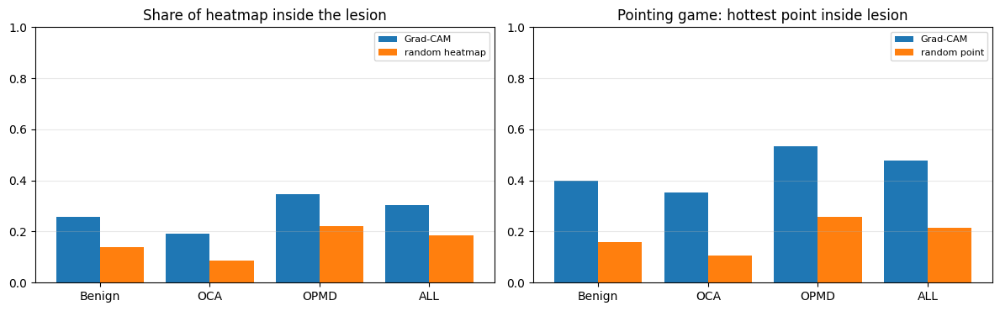

In [12]:
def load_original(i):
    r = T_df.loc[i]
    img = cv2.imread(r.orig_path, cv2.IMREAD_COLOR)
    if img is None:
        return None
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    s = DISPLAY_MAX_SIDE / max(img.shape[:2])
    return cv2.resize(img, (int(img.shape[1] * s), int(img.shape[0] * s)), interpolation=cv2.INTER_AREA), s


def geometry(i, s, shape):
    pg = polys.get(T_df.loc[i, "coco_id"], {"oral": [], "lesion": []})
    oral = [p * s for p in pg["oral"]]; lesion = [p * s for p in pg["lesion"]]
    if oral:
        allp = np.concatenate(oral); x0, y0 = allp.min(0); x1, y1 = allp.max(0)
    else:
        x0, y0, x1, y1 = 0, 0, shape[1], shape[0]
    box = [int(max(0, np.floor(x0))), int(max(0, np.floor(y0))), int(min(shape[1], np.ceil(x1))), int(min(shape[0], np.ceil(y1)))]
    les = np.zeros(shape[:2], np.uint8)
    for p in lesion:
        cv2.fillPoly(les, [np.round(p).astype(np.int32)], 1)
    return box, lesion, les.astype(bool)


def paste(cam, box, shape):
    full = np.zeros(shape[:2], np.float32)
    x0, y0, x1, y1 = box
    if x1 > x0 and y1 > y0:
        full[y0:y1, x0:x1] = cv2.resize(cam, (x1 - x0, y1 - y0), interpolation=cv2.INTER_LINEAR)
    return full


def alignment(orig, box, crop_vis):
    """Correlation between the original photo inside the box and the segmented crop (non-black pixels). ~1 = aligned."""
    x0, y0, x1, y1 = box
    if x1 - x0 < 5 or y1 - y0 < 5:
        return np.nan
    a = cv2.cvtColor(cv2.resize(orig[y0:y1, x0:x1], (crop_vis.shape[1], crop_vis.shape[0])), cv2.COLOR_RGB2GRAY).astype(float)
    b = cv2.cvtColor(crop_vis, cv2.COLOR_RGB2GRAY).astype(float)
    m = b > 12
    return float(np.corrcoef(a[m], b[m])[0, 1]) if m.sum() > 50 else np.nan


L = []
for i in T_df.index:
    o = load_original(i)
    if o is None:
        L.append(dict(align_score=np.nan)); continue
    orig, s = o
    box, lesion, les = geometry(i, s, orig.shape)
    cam_full = paste(CAMS[i][0], box, orig.shape)
    rec = dict(align_score=alignment(orig, box, CAMS[i][2]), has_lesion=bool(les.any()))
    if les.any() and cam_full.sum() > 0:
        x0, y0, x1, y1 = box
        tol = cv2.dilate(les.astype(np.uint8), np.ones((15, 15), np.uint8)).astype(bool)   # 15 px tolerance (standard)
        yy, xx = np.unravel_index(cam_full.argmax(), cam_full.shape)
        rec.update(energy_in_lesion=float(cam_full[les].sum() / cam_full.sum()),
                   energy_baseline=float(les[y0:y1, x0:x1].mean()),
                   pointing_hit=bool(tol[yy, xx]), pointing_baseline=float(tol[y0:y1, x0:x1].mean()))
    L.append(rec)
T_df = pd.concat([T_df, pd.DataFrame(L, index=T_df.index)], axis=1)

print(f"Alignment of the segmented crop with the original (median correlation): {T_df.align_score.median():.2f}  "
      f"(> 0.8 = heatmaps are placed correctly on the originals)")
if T_df.align_score.median() < 0.6:
    print("WARNING: crops do not line up with the original photos -- check figure A before using figure B.")

loc = T_df[T_df.has_lesion == True].groupby("source").agg(
    images=("stem", "size"), energy_in_lesion=("energy_in_lesion", "mean"), random_baseline=("energy_baseline", "mean"),
    pointing_game_hit=("pointing_hit", "mean"), pointing_baseline=("pointing_baseline", "mean")).round(3)
loc.loc["ALL"] = [loc.images.sum()] + [T_df[T_df.has_lesion == True][c].mean().round(3) for c in
                                       ("energy_in_lesion", "energy_baseline", "pointing_hit", "pointing_baseline")]
display(loc)
loc.to_csv(OUT_DIR / "lesion_localisation.csv")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
idx = [i for i in loc.index]; xx = np.arange(len(idx))
ax[0].bar(xx - .2, loc.energy_in_lesion, .4, label="Grad-CAM"); ax[0].bar(xx + .2, loc.random_baseline, .4, label="random heatmap")
ax[0].set_title("Share of heatmap inside the lesion"); ax[1].bar(xx - .2, loc.pointing_game_hit, .4, label="Grad-CAM")
ax[1].bar(xx + .2, loc.pointing_baseline, .4, label="random point"); ax[1].set_title("Pointing game: hottest point inside lesion")
for a in ax:
    a.set_xticks(xx); a.set_xticklabels(idx); a.set_ylim(0, 1); a.legend(fontsize=8); a.grid(axis="y", alpha=.3)
plt.tight_layout(); fig.savefig(FIG / "lesion_localisation.png", dpi=150); plt.show()

## 7. Figure A: verification (for you)
Original with the **crop box** (yellow) and **lesion outline** (cyan) · the crop the model saw · heatmap on the crop ·
the same heatmap pasted on the original · alignment score. If the pasted heatmap sits on the same structures as in the crop, the mapping is correct.

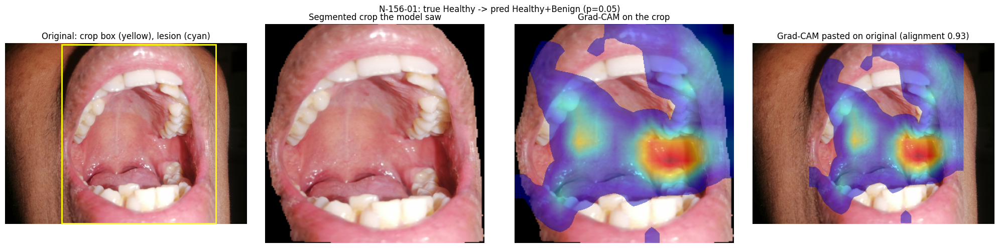

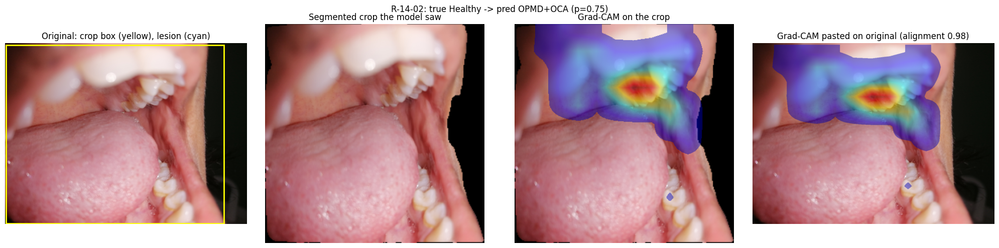

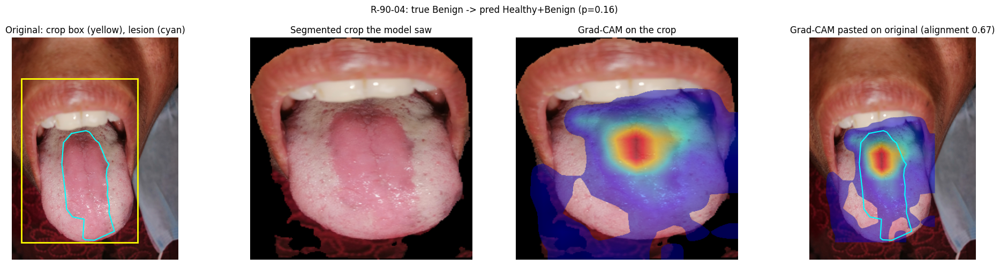

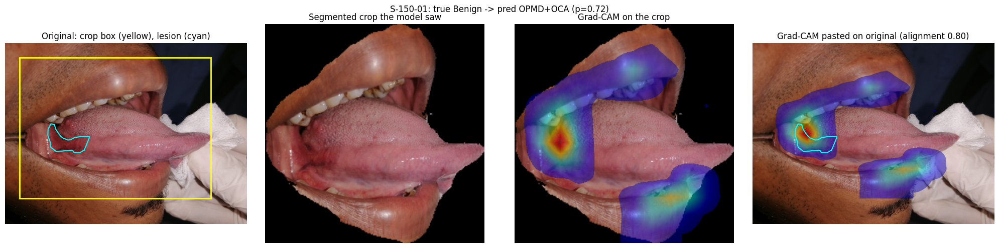

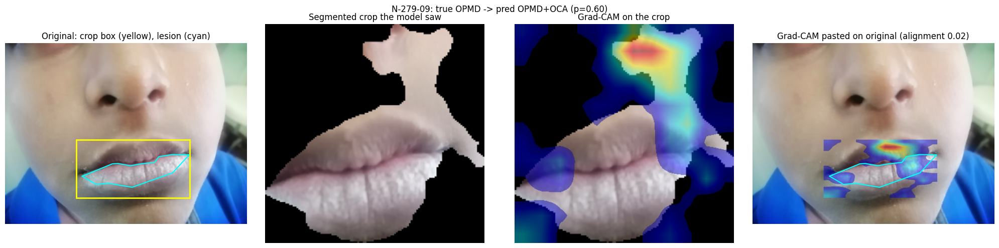

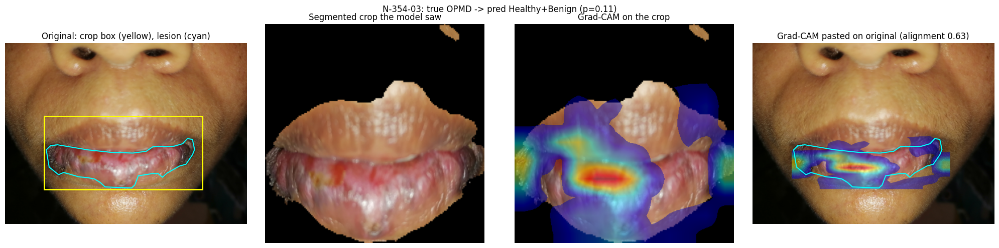

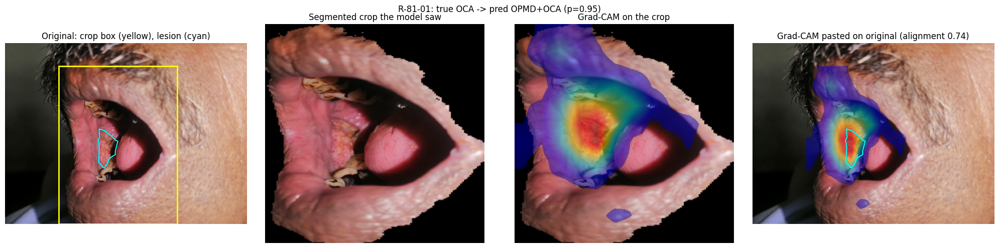

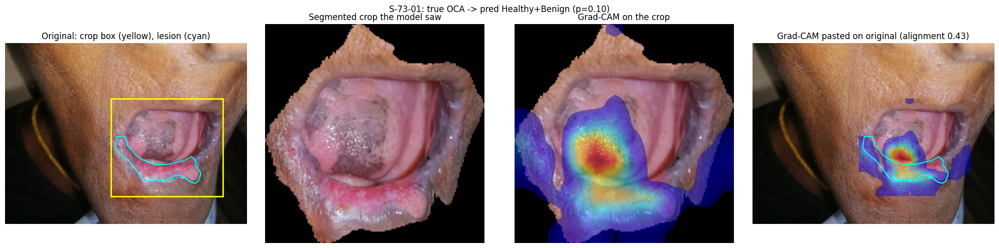

In [14]:
def overlay(img, cam, alpha=0.45):
    h = cv2.applyColorMap((np.clip(cam, 0, 1) * 255).astype(np.uint8), cv2.COLORMAP_JET)[..., ::-1]
    w = (alpha * (cam[..., None] > 0.05)).astype(np.float32)
    return (img * (1 - w) + h * w).astype(np.uint8)


def pick_examples():
    out = []
    for src in SOURCE_TO_LABEL:
        g = T_df[(T_df.source == src) & T_df.orig_path.notna()]
        good, bad = g[g.correct], g[~g.correct]
        n_bad = min(len(bad), 1 if len(good) else EXAMPLES_PER_CLASS)      # one wrong case per class when available
        n_good = min(len(good), EXAMPLES_PER_CLASS - n_bad)
        out += list(good.sample(n_good, random_state=SEED).index) + list(bad.sample(n_bad, random_state=SEED).index)
    return out


def label_txt(i):
    r = T_df.loc[i]
    return f"true {r.source} -> pred {CLASSES[r.pred]} (p={r.p_final:.2f})"


EX = pick_examples()
for i in EX:
    orig, s = load_original(i); box, lesion, _ = geometry(i, s, orig.shape)
    cam, campp, crop_vis = CAMS[i]
    full = paste(cam, box, orig.shape)
    fig, ax = plt.subplots(1, 4, figsize=(20, 5))
    ax[0].imshow(orig); ax[0].add_patch(Rectangle((box[0], box[1]), box[2] - box[0], box[3] - box[1], fill=False, ec="yellow", lw=2))
    for p in lesion:
        ax[0].plot(*np.vstack([p, p[:1]]).T, c="cyan", lw=1.5)
    ax[0].set_title("Original: crop box (yellow), lesion (cyan)")
    ax[1].imshow(crop_vis); ax[1].set_title("Segmented crop the model saw")
    ax[2].imshow(overlay(crop_vis, cam)); ax[2].set_title("Grad-CAM on the crop")
    ax[3].imshow(overlay(orig, full))
    for p in lesion:
        ax[3].plot(*np.vstack([p, p[:1]]).T, c="cyan", lw=1.5)
    ax[3].set_title(f"Grad-CAM pasted on original (alignment {T_df.loc[i, "align_score"]:.2f})")
    for a in ax:
        a.axis("off")
    fig.suptitle(f"{T_df.loc[i, 'stem']}: {label_txt(i)}"); plt.tight_layout()
    fig.savefig(FIG / "A_verification" / f"{T_df.loc[i, 'stem']}.png", dpi=110); plt.show()

## 8. Figure B: clean thesis figures on the original photo

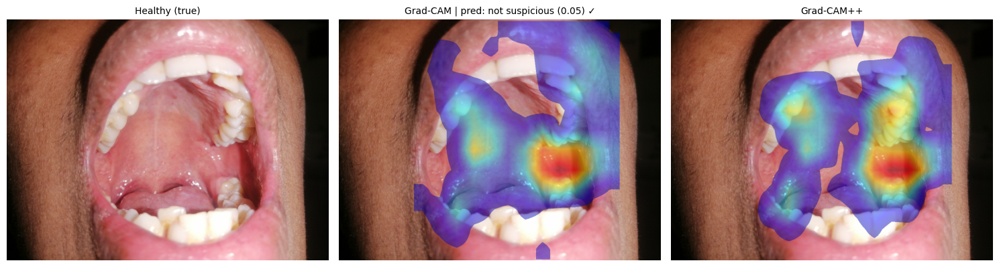

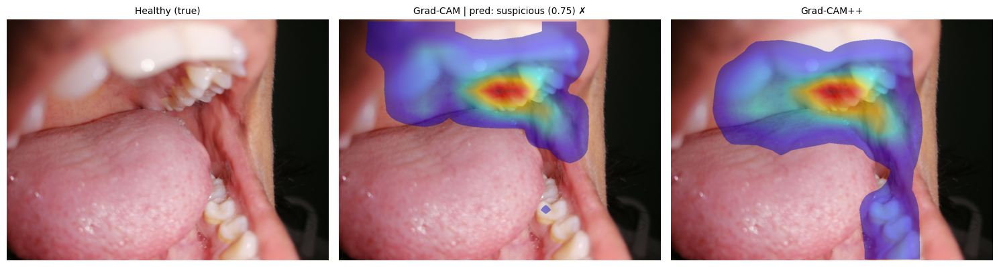

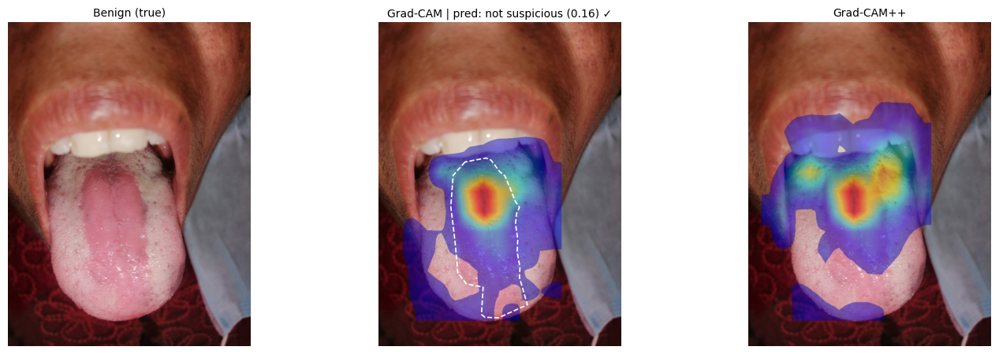

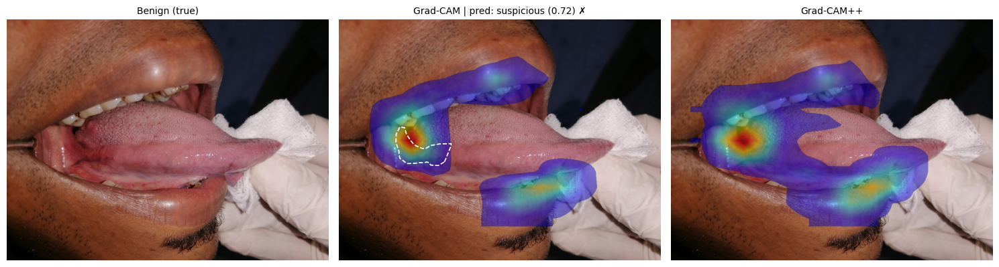

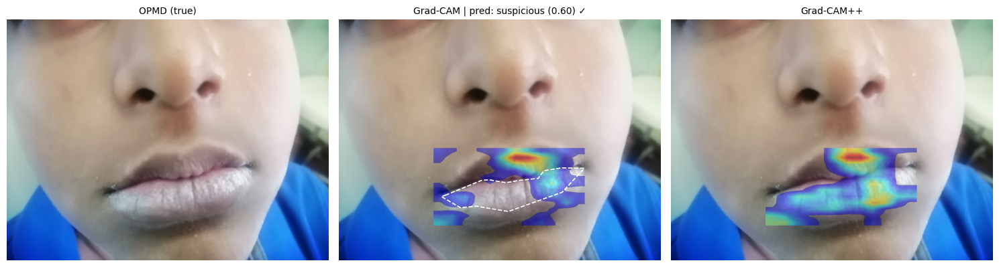

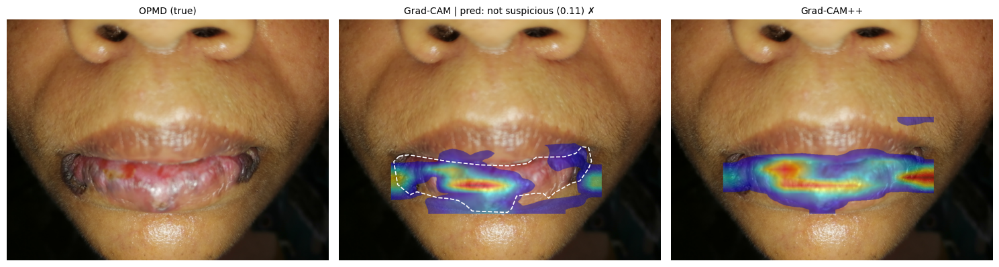

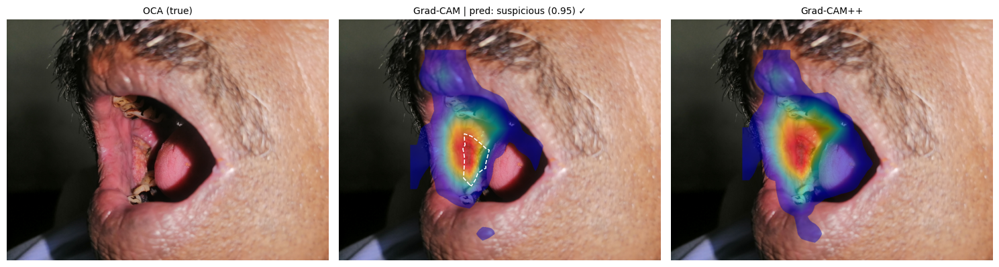

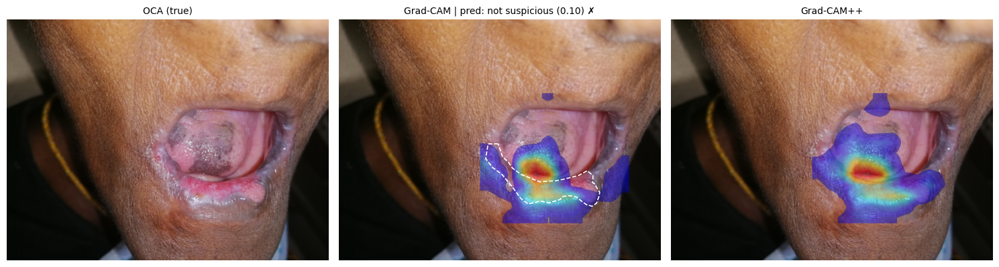

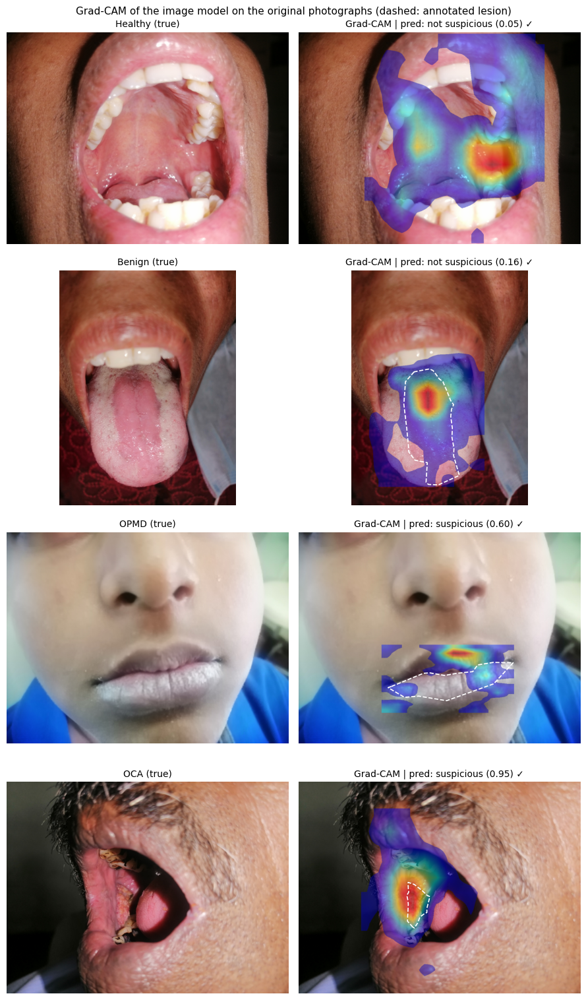

In [15]:
def thesis_panel(i, ax_o, ax_c, ax_pp=None):
    orig, s = load_original(i); box, lesion, _ = geometry(i, s, orig.shape)
    cam, campp, _ = CAMS[i]
    ax_o.imshow(orig); ax_o.set_title(f"{T_df.loc[i, 'source']} (true)", fontsize=10)
    ax_c.imshow(overlay(orig, paste(cam, box, orig.shape)))
    for p in lesion:
        ax_c.plot(*np.vstack([p, p[:1]]).T, c="white", lw=1.2, ls="--")
    r = T_df.loc[i]
    ax_c.set_title(f"Grad-CAM | pred: {'suspicious' if r.pred else 'not suspicious'} ({r.p_final:.2f})"
                   + (" ✓" if r.correct else " ✗"), fontsize=10)
    if ax_pp is not None:
        ax_pp.imshow(overlay(orig, paste(campp, box, orig.shape))); ax_pp.set_title("Grad-CAM++", fontsize=10)
    for a in (ax_o, ax_c, ax_pp):
        if a is not None:
            a.axis("off")


for i in EX:                                                    # one clean figure per example
    fig, ax = plt.subplots(1, 3, figsize=(15, 4.6)); thesis_panel(i, *ax); plt.tight_layout()
    fig.savefig(FIG / "B_thesis" / f"{T_df.loc[i, 'stem']}.png", dpi=200, bbox_inches="tight"); plt.show()

# one grid for the thesis: one example per original class (correct ones preferred)
def grid_pick(src):                                            # a correct example if there is one
    g = T_df[(T_df.source == src) & T_df.orig_path.notna()]
    g = g[g.correct] if g.correct.any() else g
    return g.sample(1, random_state=SEED).index[0]


grid = [grid_pick(s) for s in SOURCE_TO_LABEL if ((T_df.source == s) & T_df.orig_path.notna()).any()]
fig, axes = plt.subplots(len(grid), 2, figsize=(9, 3.9 * len(grid)), squeeze=False)
for row, i in zip(axes, grid):
    thesis_panel(i, row[0], row[1])
fig.suptitle("Grad-CAM of the image model on the original photographs (dashed: annotated lesion)", fontsize=11)
plt.tight_layout(); fig.savefig(FIG / "B_thesis" / "thesis_gradcam_grid.png", dpi=200, bbox_inches="tight"); plt.show()

## 9. SHAP: metadata model and image-vs-metadata share
SHAP values come from XGBoost's exact TreeSHAP (`pred_contribs`), in log-odds units (positive = towards "suspicious").
One-hot columns are summed back to one value per factor.

Average share of the final decision from the IMAGE: 59%, from METADATA: 41%


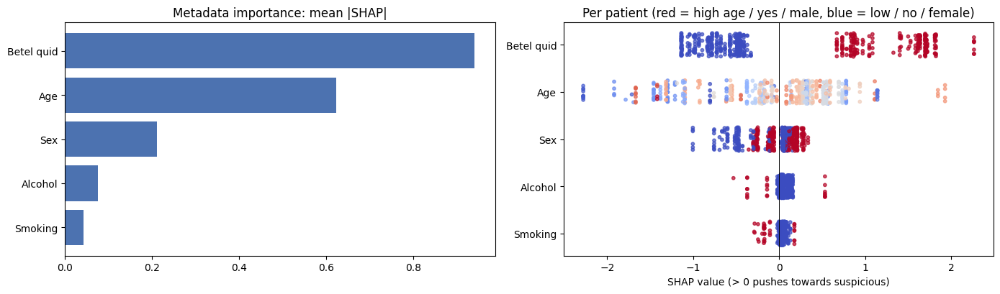

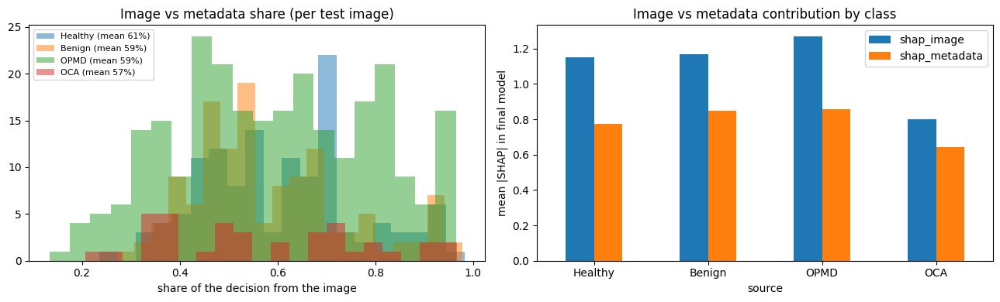

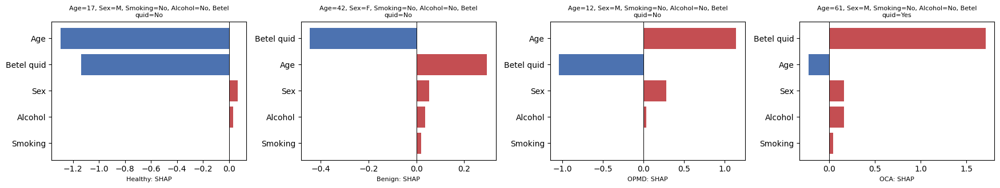

In [16]:
FACTOR = {f: f[2:].split("=")[0] for f in FEATS}
NICE = {"age": "Age", "sex": "Sex", "smoking": "Smoking", "alcohol": "Alcohol", "betel": "Betel quid"}


def shap_contribs(model, X, names):
    c = model.get_booster().predict(xgb.DMatrix(np.asarray(X, np.float32)), pred_contribs=True)
    return pd.DataFrame(c[:, :-1], columns=names), c[:, -1]


S_meta, _ = shap_contribs(meta_xgb, M_test, FEATS)
S_meta_f = S_meta.T.groupby(lambda f: NICE.get(FACTOR[f], FACTOR[f])).sum().T            # per factor
S_l4, _ = shap_contribs(l4, X_l4, ["image"] + FEATS)
T_df["shap_image"] = S_l4["image"].values
T_df["shap_metadata"] = S_l4[FEATS].sum(1).values
T_df["image_share"] = np.abs(T_df.shap_image) / (np.abs(T_df.shap_image) + np.abs(T_df.shap_metadata) + 1e-9)
print(f"Average share of the final decision from the IMAGE: {T_df.image_share.mean():.0%}, "
      f"from METADATA: {1 - T_df.image_share.mean():.0%}")

# raw factor values for colouring
raw = pd.DataFrame({NICE.get(k, k): (pd.to_numeric(T_df[c], errors="coerce") if c in ENC["encoding"]["numeric"]
                                     else T_df[c].astype(str).str.lower().isin(["yes", "y", "1", "true", "m", "male"]).astype(float))
                    for k, c in ENC["columns"].items()})

order = S_meta_f.abs().mean().sort_values().index
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
ax[0].barh(order, S_meta_f.abs().mean()[order], color="#4C72B0"); ax[0].set_title("Metadata importance: mean |SHAP|")
for k, f in enumerate(order):
    v = raw[f].values; vv = (v - np.nanmin(v)) / (np.nanmax(v) - np.nanmin(v) + 1e-9)
    ax[1].scatter(S_meta_f[f], k + rng.uniform(-.25, .25, len(v)), c=vv, cmap="coolwarm", s=10, alpha=.7)
ax[1].axvline(0, c="k", lw=.7); ax[1].set_yticks(range(len(order))); ax[1].set_yticklabels(order)
ax[1].set_xlabel("SHAP value (> 0 pushes towards suspicious)")
ax[1].set_title("Per patient (red = high age / yes / male, blue = low / no / female)")
plt.tight_layout(); fig.savefig(FIG / "shap" / "metadata_shap_summary.png", dpi=200); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for k, src in enumerate(SOURCE_TO_LABEL):
    v = T_df[T_df.source == src].image_share
    ax[0].hist(v, bins=20, alpha=.5, label=f"{src} (mean {v.mean():.0%})")
ax[0].set_xlabel("share of the decision from the image"); ax[0].legend(fontsize=8); ax[0].set_title("Image vs metadata share (per test image)")
m = T_df.groupby("source")[["shap_image", "shap_metadata"]].apply(lambda d: d.abs().mean()).loc[list(SOURCE_TO_LABEL)]
m.plot.bar(ax=ax[1], rot=0); ax[1].set_ylabel("mean |SHAP| in final model"); ax[1].set_title("Image vs metadata contribution by class")
plt.tight_layout(); fig.savefig(FIG / "shap" / "image_vs_metadata.png", dpi=200); plt.show()


def waterfall(ax, i):
    s = S_meta_f.loc[i].sort_values(key=np.abs)
    ax.barh(s.index, s.values, color=["#C44E52" if v > 0 else "#4C72B0" for v in s.values])
    ax.axvline(0, c="k", lw=.7); ax.set_xlabel("SHAP (red = towards suspicious)")
    vals = ", ".join(f"{NICE.get(k, k)}={T_df.loc[i, c]}" for k, c in ENC["columns"].items())
    ax.set_title(textwrap.fill(vals, 50), fontsize=8)


fig, axes = plt.subplots(1, len(grid), figsize=(4.4 * len(grid), 3.4), squeeze=False)
for a, i in zip(axes[0], grid):
    waterfall(a, i); a.set_xlabel(f"{T_df.loc[i, 'source']}: SHAP", fontsize=8)
plt.tight_layout(); fig.savefig(FIG / "shap" / "metadata_waterfalls.png", dpi=200); plt.show()

## 10. Failure analysis: wrong predictions explained

Wrong predictions on test: 118 | by class: {'OPMD': 83, 'Benign': 22, 'Healthy': 11, 'OCA': 2}


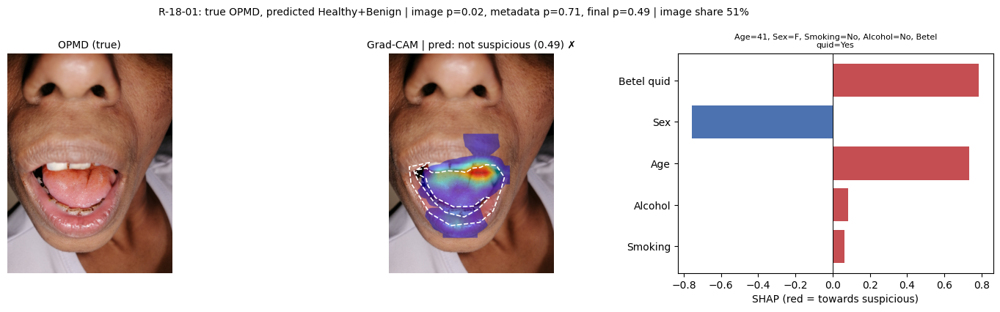

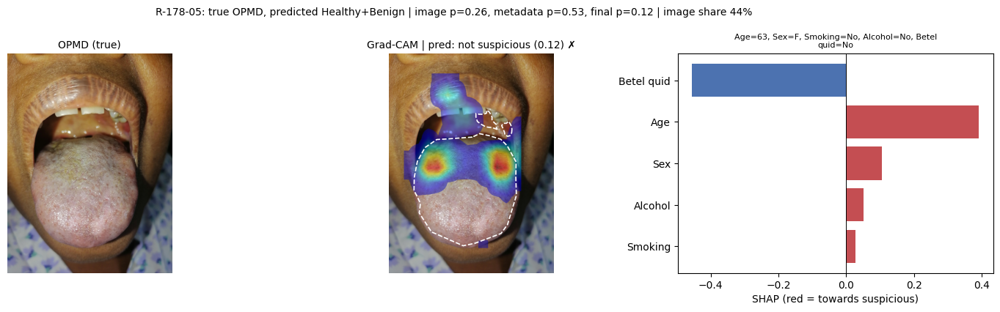

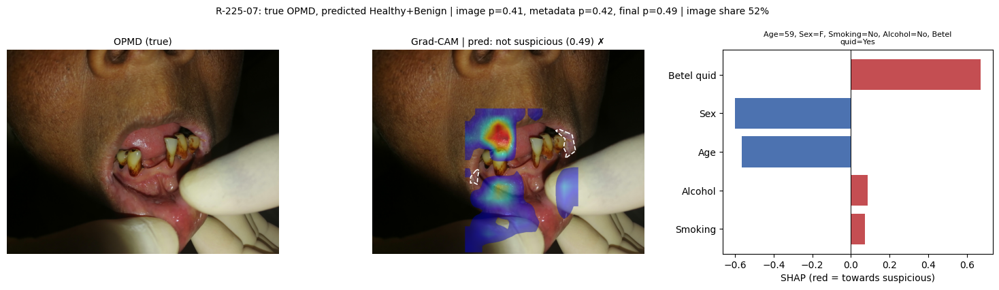

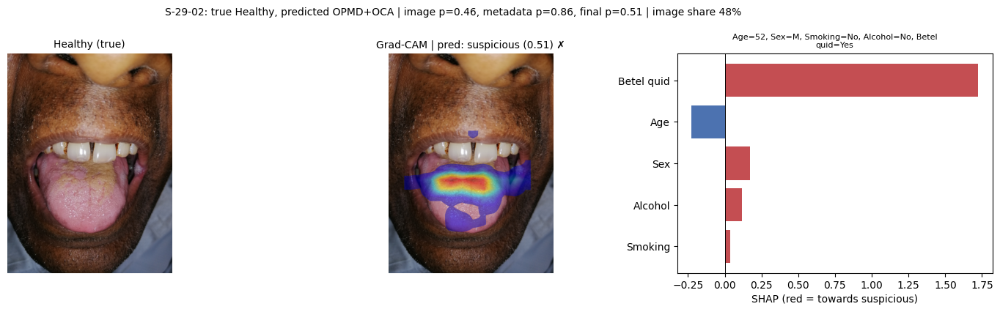

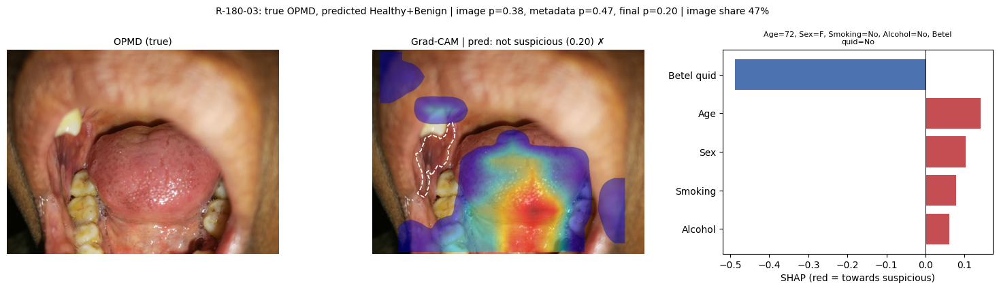

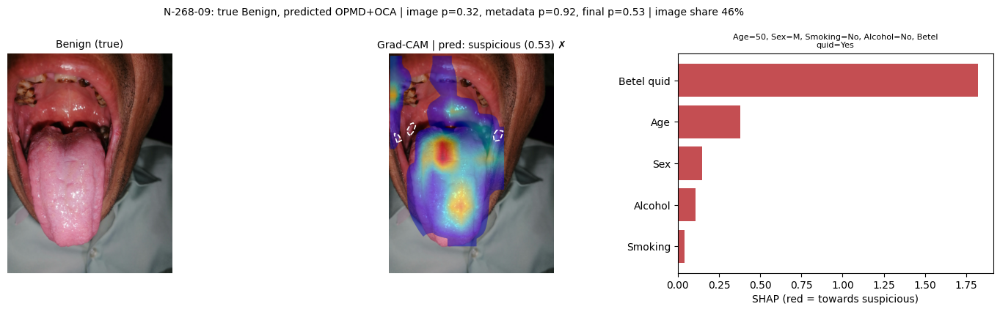

In [17]:
wrong = T_df[~T_df.correct & T_df.orig_path.notna()]
fails = list(wrong.sample(min(N_FAILURES, len(wrong)), random_state=SEED).index)
print(f"Wrong predictions on test: {len(wrong)} | by class: {wrong.source.value_counts().to_dict()}")
for i in fails:
    fig = plt.figure(figsize=(15, 4.3)); gs = fig.add_gridspec(1, 3, width_ratios=[1, 1, .9])
    a0, a1, a2 = fig.add_subplot(gs[0]), fig.add_subplot(gs[1]), fig.add_subplot(gs[2])
    thesis_panel(i, a0, a1); waterfall(a2, i)
    r = T_df.loc[i]
    fig.suptitle(f"{r.stem}: true {r.source}, predicted {CLASSES[r.pred]} | image p={r.p_image:.2f}, metadata p={r.p_meta:.2f}, "
                 f"final p={r.p_final:.2f} | image share {r.image_share:.0%}", fontsize=10)
    plt.tight_layout(); fig.savefig(FIG / "failures" / f"{r.stem}.png", dpi=150); plt.show()

## 11. Per-patient explanation cards (what the website would show)

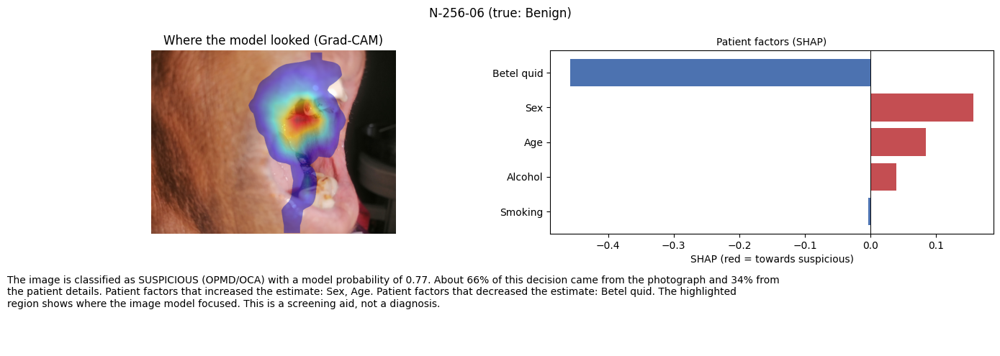

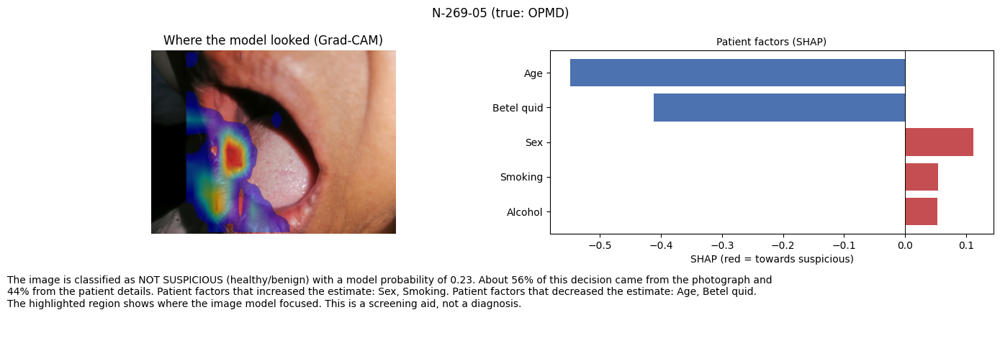

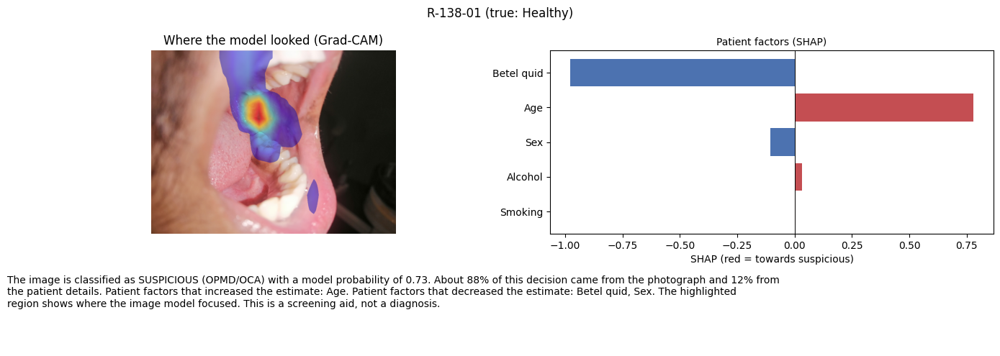

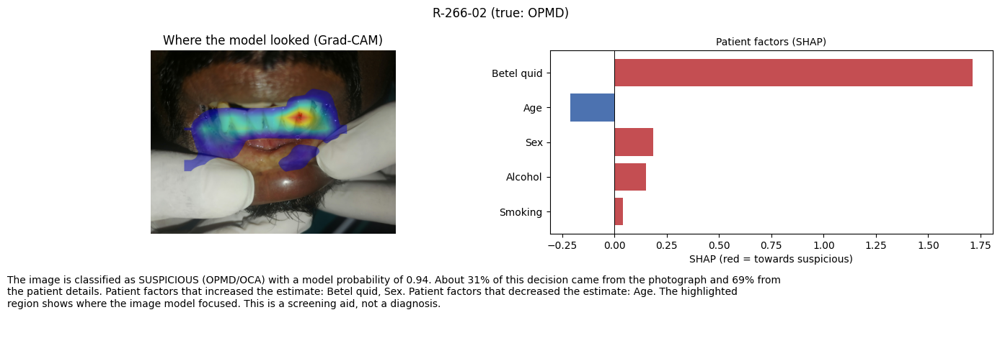

Saved: /kaggle/working/explainability/per_image_explanations.csv | figures in /kaggle/working/explainability/figures


In [18]:
def explanation_text(i):
    r = T_df.loc[i]
    s = S_meta_f.loc[i]
    up = [f for f in s.sort_values(ascending=False).index if s[f] > 0.05][:2]
    down = [f for f in s.sort_values().index if s[f] < -0.05][:2]
    lines = [f"The image is classified as {'SUSPICIOUS (OPMD/OCA)' if r.pred else 'NOT SUSPICIOUS (healthy/benign)'} "
             f"with a model probability of {r.p_final:.2f}.",
             f"About {r.image_share:.0%} of this decision came from the photograph and {1 - r.image_share:.0%} from the patient details."]
    if up:
        lines.append("Patient factors that increased the estimate: " + ", ".join(up) + ".")
    if down:
        lines.append("Patient factors that decreased the estimate: " + ", ".join(down) + ".")
    lines.append("The highlighted region shows where the image model focused.")
    lines.append("This is a screening aid, not a diagnosis.")
    return " ".join(lines)


cards = list(T_df[T_df.orig_path.notna()].sample(min(N_CARDS, len(T_df)), random_state=SEED + 1).index)
for i in cards:
    fig = plt.figure(figsize=(14, 5)); gs = fig.add_gridspec(2, 2, height_ratios=[3, 1.2], width_ratios=[1.2, 1])
    a0 = fig.add_subplot(gs[0, 0]); a1 = fig.add_subplot(gs[0, 1]); a2 = fig.add_subplot(gs[1, :])
    orig, s = load_original(i); box, lesion, _ = geometry(i, s, orig.shape)
    a0.imshow(overlay(orig, paste(CAMS[i][0], box, orig.shape))); a0.axis("off"); a0.set_title("Where the model looked (Grad-CAM)")
    waterfall(a1, i); a1.set_title("Patient factors (SHAP)", fontsize=10)
    a2.axis("off"); a2.text(0, 1, textwrap.fill(explanation_text(i), 150), va="top", fontsize=10)
    fig.suptitle(f"{T_df.loc[i, 'stem']} (true: {T_df.loc[i, 'source']})"); plt.tight_layout()
    fig.savefig(FIG / "cards" / f"{T_df.loc[i, 'stem']}.png", dpi=150); plt.show()

T_df["explanation"] = [explanation_text(i) for i in T_df.index]
keep = ["stem", "source", "label", "pred", "correct", "p_image", "p_meta", "p_final", "image_share", "align_score",
        "energy_in_lesion", "energy_baseline", "pointing_hit", "cam_vs_campp_corr", "explanation"]
T_df[keep].to_csv(OUT_DIR / "per_image_explanations.csv", index=False)
print("Saved:", OUT_DIR / "per_image_explanations.csv", "| figures in", FIG)

## Reading the results
- **Alignment** close to 1 means the heatmaps were placed correctly on the original photos (check figure A first).
- **Energy in lesion / pointing game above the random baseline** means the image model concentrates on the lesion more than chance.
  Values near the baseline mean it relies on other regions (teeth, lips, colour), which is worth reporting honestly.
- **Grad-CAM vs Grad-CAM++ correlation** shows whether the two methods agree; high agreement makes the heatmaps more trustworthy.
- **SHAP** explains the *model*, not the disease: a factor with a large SHAP value influenced the prediction, not necessarily the diagnosis.